# Phase 3A  Dataset Cleaning

In [3]:
# ===========================================
# Import Required Libraries
# ===========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Plot style
plt.style.use('ggplot')

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
# ===========================================
# Load Dataset
# ===========================================

file_path = "/content/drive/MyDrive/My Thesis/air_quality_Updated.xlsx"

air = pd.read_excel(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


#PM2.5 Cleaning Process

In [6]:
# ==========================
# Preserve the original data
# ==========================

air_raw = air.copy(deep=True)

# Create a working dataset
air_clean = air_raw.copy(deep=True)

In [7]:
# Missing values before imputation
print("Missing PM2.5 values:", air_clean["PM2.5"].isna().sum())

Missing PM2.5 values: 556


In [8]:
# Ensure date is the index
air_clean = air_clean.set_index("date")

# Time-based interpolation
air_clean["PM2.5"] = air_clean["PM2.5"].interpolate(
    method="time",
    limit_direction="both"
)

In [9]:
print("Missing PM2.5 values after interpolation:",
      air_clean["PM2.5"].isna().sum())

Missing PM2.5 values after interpolation: 0


In [10]:
air_clean["PM2.5"].describe()

,PM2.5
count,17544.000000
mean,24.724431
std,27.088971
min,1.540185
25%,12.329761
50%,17.274526
75%,26.921815
max,249.604800


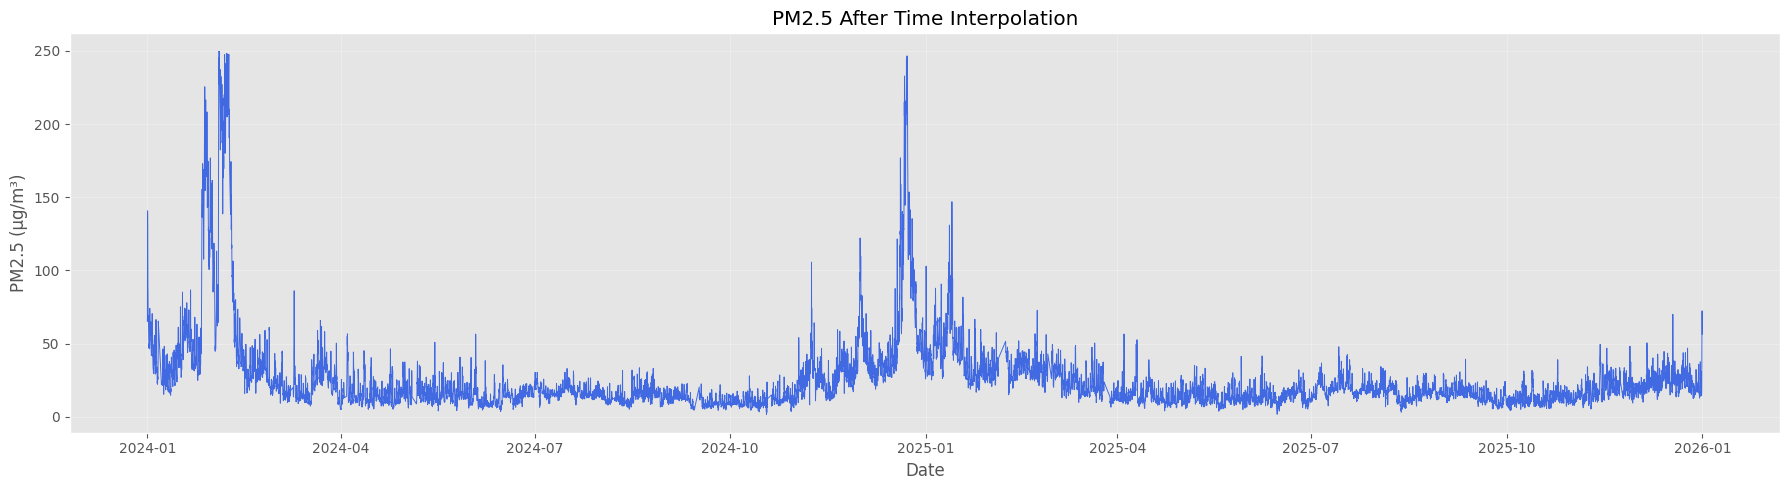

In [11]:
plt.figure(figsize=(18,5))

plt.plot(
    air_clean.index,
    air_clean["PM2.5"],
    linewidth=0.7,
    color="royalblue"
)

plt.title("PM2.5 After Time Interpolation")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

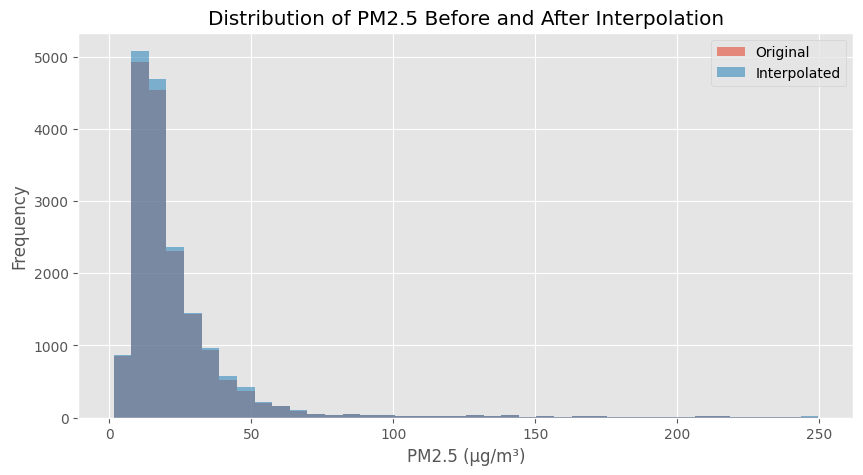

In [12]:
plt.figure(figsize=(10,5))

plt.hist(air_raw['PM2.5'].dropna(), bins=40, alpha=0.6, label="Original")
plt.hist(air_clean["PM2.5"], bins=40, alpha=0.6, label="Interpolated")

plt.title("Distribution of PM2.5 Before and After Interpolation")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [13]:
print(air_clean["PM2.5"].describe())

print("\nSkewness :", air_clean["PM2.5"].skew())
print("Kurtosis :", air_clean["PM2.5"].kurt())

count    17544.000000
mean        24.724431
std         27.088971
min          1.540185
25%         12.329761
50%         17.274526
75%         26.921815
max        249.604800
Name: PM2.5, dtype: float64

Skewness : 4.677941866580866
Kurtosis : 27.01307135740163


# PM10 Missing Value Treatment

In [14]:
# Missing PM10 observations
print("Missing PM10 values:", air_clean["PM10"].isna().sum())

Missing PM10 values: 537


In [15]:
# Consecutive missing gap lengths
pm10_gap_lengths = (
    air_clean["PM10"]
    .isna()
    .astype(int)
    .groupby(air_clean["PM10"].notna().cumsum())
    .sum()
)

pm10_gap_lengths = pm10_gap_lengths[pm10_gap_lengths > 0]

pm10_gap_lengths.describe()

,PM10
count,30.000000
mean,17.900000
std,22.342707
min,1.000000
25%,1.000000
50%,4.500000
75%,28.750000
max,81.000000


In [16]:
pm10_gap_lengths.sort_values(ascending=False).head(20)

,PM10
PM10,
9326,81
10396,67
6005,55
2888,48
6774,46
9803,36
124,32
16117,29
1576,28


In [17]:
# Find the start and end dates of each missing block
pm10_missing = air_clean["PM10"].isna()

groups = (pm10_missing != pm10_missing.shift()).cumsum()

gap_info = (
    air_clean[pm10_missing]
    .groupby(groups[pm10_missing])
    .apply(lambda x: pd.Series({
        "Start": x.index.min(),
        "End": x.index.max(),
        "Length": len(x)
    }))
)

gap_info.sort_values("Length", ascending=False).head(10)

,Start,End,Length
PM10,,,
36,2025-02-04 02:00:00,2025-02-07 10:00:00,81
42,2025-03-25 18:00:00,2025-03-28 12:00:00,67
22,2024-09-14 03:00:00,2024-09-16 09:00:00,55
16,2024-05-04 11:00:00,2024-05-06 10:00:00,48
26,2024-10-18 12:00:00,2024-10-20 09:00:00,46
38,2025-02-27 08:00:00,2025-02-28 19:00:00,36
2,2024-01-06 04:00:00,2024-01-07 11:00:00,32
54,2025-11-23 11:00:00,2025-11-24 15:00:00,29
6,2024-03-08 09:00:00,2024-03-09 12:00:00,28


In [18]:
gap = air_clean.loc[
    "2025-02-04 02:00":"2025-02-07 10:00",
    ["PM10", "PM2.5"]
]

gap

,PM10,PM2.5
date,,
2025-02-04 02:00:00,NaN,39.918167
2025-02-04 03:00:00,NaN,40.062050
2025-02-04 04:00:00,NaN,40.205934
2025-02-04 05:00:00,NaN,40.349817
2025-02-04 06:00:00,NaN,40.493701
...,...,...
2025-02-07 06:00:00,NaN,50.853311
2025-02-07 07:00:00,NaN,50.997195
2025-02-07 08:00:00,NaN,51.141078


In [19]:
gap.isna().sum()

,0
PM10,81
PM2.5,0


In [20]:
air_clean[["PM2.5", "PM10"]].corr()

,PM2.5,PM10
PM2.5,1.000000,0.973476
PM10,0.973476,1.000000


In [21]:
air_clean["Temp"] = air_clean["Temp"].interpolate(
    method="time",
    limit_direction="both"
)

In [22]:
air_clean["Temp"].isna().sum()

np.int64(0)

In [26]:
# Find consecutive missing gaps for WD
mask = air_clean["WD"].isna()

groups = (mask != mask.shift()).cumsum()

wd_gaps = (
    air_clean[mask]
    .groupby(groups)
    .apply(lambda x: pd.Series({
        "Start": x.index.min(),
        "End": x.index.max(),
        "Length": len(x)
    }))
    .sort_values("Length", ascending=False)
)

wd_gaps.head(10)

,Start,End,Length
WD,,,
10,2024-10-18 12:00:00,2024-10-20 09:00:00,46
8,2024-04-02 17:00:00,2024-04-03 15:00:00,23
18,2025-05-05 12:00:00,2025-05-06 09:00:00,22
34,2025-10-01 20:00:00,2025-10-02 03:00:00,8
24,2025-09-12 18:00:00,2025-09-13 01:00:00,8
46,2025-10-07 15:00:00,2025-10-07 22:00:00,8
42,2025-10-06 00:00:00,2025-10-06 05:00:00,6
26,2025-09-13 03:00:00,2025-09-13 07:00:00,5
2,2024-03-18 18:00:00,2024-03-18 21:00:00,4


In [28]:
wd_gaps.head(10)

,Start,End,Length
WD,,,
10,2024-10-18 12:00:00,2024-10-20 09:00:00,46
8,2024-04-02 17:00:00,2024-04-03 15:00:00,23
18,2025-05-05 12:00:00,2025-05-06 09:00:00,22
34,2025-10-01 20:00:00,2025-10-02 03:00:00,8
24,2025-09-12 18:00:00,2025-09-13 01:00:00,8
46,2025-10-07 15:00:00,2025-10-07 22:00:00,8
42,2025-10-06 00:00:00,2025-10-06 05:00:00,6
26,2025-09-13 03:00:00,2025-09-13 07:00:00,5
2,2024-03-18 18:00:00,2024-03-18 21:00:00,4


In [29]:
air_clean.loc[
    "2024-10-18 06:00":"2024-10-20 15:00",
    ["WD"]
]

,WD
date,
2024-10-18 06:00:00,92.535981
2024-10-18 07:00:00,254.239153
2024-10-18 08:00:00,268.530000
2024-10-18 09:00:00,234.061667
2024-10-18 10:00:00,187.885000
2024-10-18 11:00:00,194.755263
2024-10-18 12:00:00,NaN
2024-10-18 13:00:00,NaN
2024-10-18 14:00:00,NaN


In [30]:
air_clean["WD"] = air_clean["WD"].interpolate(
    method="time",
    limit_direction="both"
)

In [31]:
air_clean["WD"].isna().sum()


np.int64(0)

# Wind Speed (m/s) Cleaning

In [32]:
# Consecutive missing gaps for Wind Speed

mask = air_clean["WS"].isna()

groups = (mask != mask.shift()).cumsum()

ws_gaps = (
    air_clean[mask]
    .groupby(groups)
    .apply(lambda x: pd.Series({
        "Start": x.index.min(),
        "End": x.index.max(),
        "Length": len(x)
    }))
    .sort_values("Length", ascending=False)
)

ws_gaps.head(10)

,Start,End,Length
WS,,,
66,2025-08-30 04:00:00,2025-09-10 05:00:00,266
122,2025-10-19 10:00:00,2025-10-28 19:00:00,226
140,2025-11-14 06:00:00,2025-11-23 09:00:00,220
124,2025-10-28 21:00:00,2025-11-03 21:00:00,145
136,2025-11-07 12:00:00,2025-11-13 10:00:00,143
84,2025-09-16 00:00:00,2025-09-21 12:00:00,133
100,2025-09-26 21:00:00,2025-10-01 14:00:00,114
118,2025-10-10 16:00:00,2025-10-15 07:00:00,112
120,2025-10-15 11:00:00,2025-10-19 07:00:00,93


In [33]:
corr = air_clean[
    ["WS", "Temp", "WD", "PM2.5", "PM10"]
].corr()

corr["WS"].sort_values(ascending=False)

,WS
WS,1.000000
Temp,0.252570
PM10,0.004991
PM2.5,-0.010378
WD,-0.147389


# Machine Learning-Based Missing Value Imputation

In [34]:
# Create a copy for PM10 imputation
pm10_data = air_clean.copy()

# Training dataset (rows with observed PM10)
train_pm10 = pm10_data[pm10_data["PM10"].notna()].copy()

# Dataset requiring prediction
predict_pm10 = pm10_data[pm10_data["PM10"].isna()].copy()

print("Training observations:", len(train_pm10))
print("Missing PM10 observations:", len(predict_pm10))

Training observations: 17007
Missing PM10 observations: 537


In [35]:
features = [
    "PM2.5",
    "Temp",
    "WD",
    "WS"
]

target = "PM10"

In [36]:
X = train_pm10[features]
y = train_pm10[target]

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(13605, 4)
(3402, 4)


In [38]:
from sklearn.ensemble import RandomForestRegressor

rf_pm10 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_pm10.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [39]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

pred = rf_pm10.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.4f}")

MAE : 8.59
RMSE: 21.19
R²  : 0.9665


In [41]:
importance = (
    pd.Series(
        rf_pm10.feature_importances_,
        index=features
    )
    .sort_values(ascending=False)
)

print(importance)

PM2.5    0.972149
Temp     0.010825
WS       0.010790
WD       0.006236
dtype: float64


In [42]:
# Train on all observed PM10 data
rf_pm10.fit(
    train_pm10[features],
    train_pm10[target]
)

# Predict missing PM10 values
predicted_pm10 = rf_pm10.predict(
    predict_pm10[features]
)

# Fill missing values
pm10_data.loc[
    pm10_data["PM10"].isna(),
    "PM10"
] = predicted_pm10

In [43]:
pm10_data["PM10"].isna().sum()

np.int64(0)

In [44]:
# Update the air_clean datase

air_clean["PM10"] = pm10_data["PM10"]
air_clean.isna().sum()

,0
PM10,0
PM2.5,0
RH,9217
Temp,0
WD,0
WS,2281


# Relative Humidity Cleaning Process

In [45]:
corr = air_clean[
    ["RH", "Temp", "PM2.5", "PM10", "WD", "WS"]
].corr()

corr["RH"].sort_values(ascending=False)

,RH
RH,1.000000
WD,0.261499
WS,-0.073299
PM2.5,-0.384522
PM10,-0.403401
Temp,-0.733346


In [46]:
rh_data = air_clean.copy()

train_rh = rh_data[rh_data["RH"].notna()].copy()

predict_rh = rh_data[rh_data["RH"].isna()].copy()

print("Training rows:", len(train_rh))
print("Rows to predict:", len(predict_rh))

Training rows: 8327
Rows to predict: 9217


In [47]:
features = [
    "Temp",
    "PM2.5",
    "PM10",
    "WD",
    "WS"
]

target = "RH"

In [49]:
from sklearn.model_selection import train_test_split

X = train_rh[features]
y = train_rh[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [50]:
from sklearn.ensemble import RandomForestRegressor

rf_rh = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_rh.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [52]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

pred = rf_rh.predict(X_test)

print("MAE :", round(mean_absolute_error(y_test, pred),2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test,pred)),2))
print("R²  :", round(r2_score(y_test,pred),4))

MAE : 3.51
RMSE: 4.86
R²  : 0.8362


In [51]:
importance = (
    pd.Series(
        rf_rh.feature_importances_,
        index=features
    )
    .sort_values(ascending=False)
)

print(importance)

Temp     0.632900
PM10     0.166098
WD       0.078931
WS       0.077980
PM2.5    0.044090
dtype: float64


In [53]:
#Now Training all dataset
rf_rh.fit(
    train_rh[features],
    train_rh[target]
)

predicted_rh = rf_rh.predict(
    predict_rh[features]
)

rh_data.loc[
    rh_data["RH"].isna(),
    "RH"
] = predicted_rh

In [55]:
# Update the dataset
air_clean["RH"] = rh_data["RH"]
air_clean.isna().sum()

,0
PM10,0
PM2.5,0
RH,0
Temp,0
WD,0
WS,2281


In [56]:
# Save the cleaned dataset
air_clean.reset_index().to_csv(
    "air_quality_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [57]:
import os

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/cleaned", exist_ok=True)
os.makedirs("data/featured", exist_ok=True)

In [58]:
air_clean.reset_index().to_csv(
    "data/cleaned/air_quality_cleaned.csv",
    index=False
)